<a href="https://colab.research.google.com/github/estefania-apaza/DocSM-Uribe/blob/main/02_EHA_GitHub_DocSM_Uribe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Event History Analysis (EHA)
## Permanencia de ministros de Educación en el Perú


## EHA-01 — Leer la base preparada

In [49]:
import pandas as pd
import numpy as np

# Cargamos la base procesada desde GitHub
url_eha = "https://raw.githubusercontent.com/estefania-apaza/DocSM-Uribe/main/eha_procesada.csv"
eha = pd.read_csv(url_eha)

print("Gestiones:", len(eha))
display(eha.head())

Gestiones: 49


,id_gestion,duracion_meses,salida_evento,designacion_constitucional,congreso_cuestiona,salida_con_presidente,vinculo_partidario,edad,otros_eventos_bin,huelgas_bin
0,1,6.3,1,1,0,0,1,67,1,0
1,2,30.3,1,1,0,0,1,54,1,0
2,3,7.9,1,1,0,0,1,59,1,0
3,4,6.1,1,1,0,0,1,48,0,1
4,5,9.5,1,1,0,1,1,62,1,0


## EHA-02 — Reconocer eventos y casos censurados

`salida_evento = 1` significa que la gestión terminó; `0`, que seguía vigente al cierre de la observación. Verificamos los valores antes de continuar.

In [50]:
resumen_eventos = (
    eha["salida_evento"]
    .value_counts(dropna=False)
    .rename(index={1: "Salida observada", 0: "Censurado"})
)
print(resumen_eventos)

salida_evento
Salida observada    49
Name: count, dtype: int64


## EHA-03 — Estimar la supervivencia general

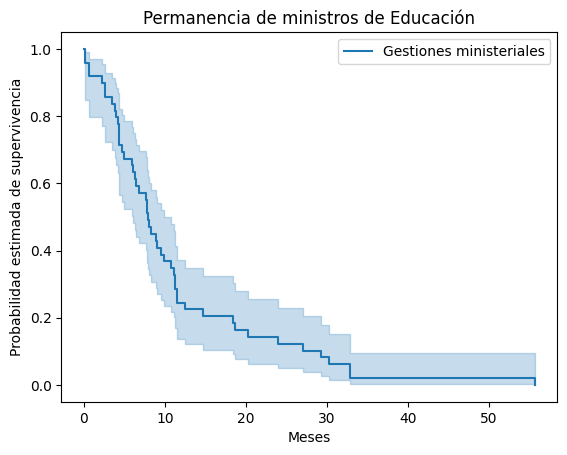

Supervivencia estimada después de 20 meses: 0.16


In [51]:
!pip install lifelines --quiet

import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

km = KaplanMeierFitter()
km.fit(
    durations=eha["duracion_meses"],
    event_observed=eha["salida_evento"],
    label="Gestiones ministeriales"
)

km.plot_survival_function()
plt.xlabel("Meses")
plt.ylabel("Probabilidad estimada de supervivencia")
plt.title("Permanencia de ministros de Educación")
plt.show()

tiempo = 20  # Podemos cambiar el número de meses
print(f"Supervivencia estimada después de {tiempo} meses:", round(km.predict(tiempo), 2))

## EHA-04 — Comparar curvas según tipo de designación


designacion_constitucional
1    34
0    15
Name: count, dtype: int64


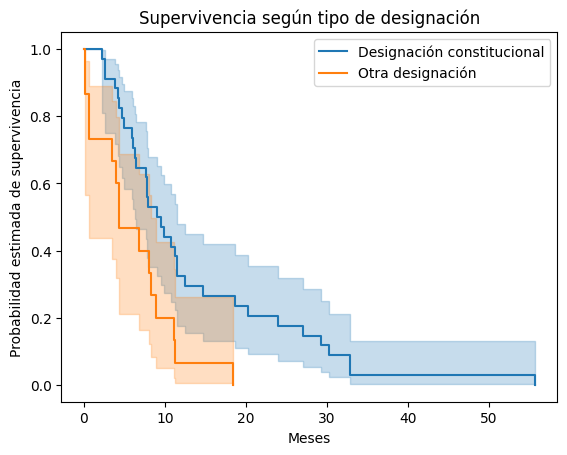

Mediana constitucional: 9.0
Mediana otra designación: 4.4


In [52]:
print(eha["designacion_constitucional"].value_counts(dropna=False))

ax = plt.subplot(111)
constitucional = eha["designacion_constitucional"] == 1

km.fit(
    eha.loc[constitucional, "duracion_meses"],
    event_observed=eha.loc[constitucional, "salida_evento"],
    label="Designación constitucional"
)
km.plot_survival_function(ax=ax)
mediana_constitucional = km.median_survival_time_

km.fit(
    eha.loc[~constitucional, "duracion_meses"],
    event_observed=eha.loc[~constitucional, "salida_evento"],
    label="Otra designación"
)
km.plot_survival_function(ax=ax)
mediana_otra = km.median_survival_time_

plt.xlabel("Meses")
plt.ylabel("Probabilidad estimada de supervivencia")
plt.title("Supervivencia según tipo de designación")
plt.show()

print("Mediana constitucional:", mediana_constitucional)
print("Mediana otra designación:", mediana_otra)

## EHA-05 — Evaluar diferencias con Log-Rank

In [53]:
from lifelines.statistics import logrank_test

logrank = logrank_test(
    eha.loc[constitucional, "duracion_meses"],
    eha.loc[~constitucional, "duracion_meses"],
    event_observed_A=eha.loc[constitucional, "salida_evento"],
    event_observed_B=eha.loc[~constitucional, "salida_evento"]
)

print("p-valor Log-Rank:", round(logrank.p_value, 4))

p-valor Log-Rank: 0.0064


## EHA-06 — Modelar el riesgo de salida (Cox)

In [54]:

from lifelines import CoxPHFitter

# Seleccionamos las variables para el modelo
eha_cox = eha[
    [
        "duracion_meses",
        "salida_evento",
        "designacion_constitucional",
        "congreso_cuestiona",
        "salida_con_presidente",
        "vinculo_partidario",
        "edad",
        "otros_eventos_bin"
    ]
].copy()

# Estimamos el modelo de Cox
cox = CoxPHFitter()

cox.fit(
    eha_cox,
    duration_col="duracion_meses",
    event_col="salida_evento"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 49 total observations, 0 right-censored observations>
             duration col = 'duracion_meses'
                event col = 'salida_evento'
      baseline estimation = breslow
   number of observations = 49
number of events observed = 49
   partial log-likelihood = -135.35
         time fit was run = 2026-10-17 18:40:23 UTC

---
                            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                   
designacion_constitucional -1.05      0.35      0.40           -1.83           -0.26                0.16                0.77
congreso_cuestiona         -0.51      0.60      0.44           -1.38            0.35                0.25                1.42
salida_con_presidente      -0.28      0.75      0.35           -0.97            0.40                0.38                1.50
vinculo_partidario         -0.29      0.74      0.40           -1.07            0.48                0.34                1.62
edad                        0.05      1.05      0.02            0.02            0.09                1.02                1.09
otros_eventos_bin           0.16      1.17      0.41           -0.65            0.97                0.52                2.63

                            cmp to     z      p  -log2(p)
covariate                                                
designacion_constitucional    0.00 -2.60   0.01      6.75
congreso_cuestiona            0.00 -1.17   0.24      2.04
salida_con_presidente         0.00 -0.80   0.42      1.25
vinculo_partidario            0.00 -0.74   0.46      1.13
edad                          0.00  2.87 <0.005      7.94
otros_eventos_bin             0.00  0.39   0.70      0.51
---
Concordance = 0.66
Partial AIC = 282.71
log-likelihood ratio test = 18.42 on 6 df
-log2(p) of ll-ratio test = 7.57

## EHA-07 — Extraer los Hazard Ratios

`HR > 1` indica mayor riesgo instantáneo de salida; `HR < 1`, menor riesgo, manteniendo constantes las otras variables. No implica causalidad por sí solo.

In [55]:
resultado_hr = pd.DataFrame({
    "HR": cox.hazard_ratios_,
    "p_valor": cox.summary["p"]
}).round(3)

display(resultado_hr)

,HR,p_valor
covariate,,
designacion_constitucional,0.351,0.009
congreso_cuestiona,0.598,0.244
salida_con_presidente,0.755,0.421
vinculo_partidario,0.745,0.456
edad,1.054,0.004
otros_eventos_bin,1.173,0.700


## EHA-08 — Comprobar el supuesto de riesgos proporcionales

In [56]:
cox.check_assumptions(
    eha_cox,
    p_value_threshold=0.05,
    show_plots=False
)

Proportional hazard assumption looks okay.


[]